# Training EDA: claim frequency per policy

**The problem.** How many claims are expected for different vehicle, driver and regional profiles, given the length of coverage? This question is studied using records from a French motor insurance portfolio (Dutang & Charpentier, 2018).

**Why it matters.** A policy covered for one year contributes one policy-year of exposure. Two claims observed over 20 policy-years correspond to 10 per 100 policy-years. If the same two claims are observed over 100 policy-years, the rate is 2 per 100. Groups with different coverage durations can therefore be compared on the same scale. Even when the predicted portfolio rate is close to the observed rate, some segments can still be underpredicted or overpredicted.

**The role of this notebook.** Claim counts (`ClaimNb`), coverage duration (`Exposure`), and observed rates by profile and exposure band are examined in the **training** partition. Each rate is calculated as `100 × Σ ClaimNb / Σ Exposure`. This analysis prepares the later comparison of observed and predicted rates by segment.

In [1]:
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("retina")
import pandas as pd
from IPython.display import display

from freq_sinistros import artifacts, eda, plots
from freq_sinistros.data import load_partitions

LANG = "en_us"
ROOT = artifacts.project_root()
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 20

## 1. Origin, unit and partition

**Question.** Which file, which observation unit and which partition support this analysis?

In [2]:
parts, provenance = load_partitions(ROOT, keep=("train",))
train = parts["train"]
display(artifacts.provenance_table(provenance, len(train), LANG))

,item,value
0,ARFF SHA-256,a45363e056e2ea56408b38eeb9d4d04d7f6c6982eb7a14...
1,assignments SHA-256,f14f53509d63ff468f025fd43096a5c2d12ba3fdd48529...
2,partition rule,bucket = int.from_bytes(sha256(utf8('freMTPL2f...
3,partition used,train
4,training records,"474,581"
5,observation unit,coverage record (IDpol)


### Insights

The raw file from OpenML 41214, version 1 (`freMTPL2freq`), was checked by SHA-256 against the acquisition manifest. The audit confirmed 678,013 distinct `IDpol` values and no missing values. Each row represents a coverage record, with duration measured in years (Dutang & Charpentier, 2018).

In stage 2 of the project, the records were split approximately **70% for training, 15% for validation, and 15% for testing**. Assignments were made deterministically using a SHA-256 hash of `IDpol`, independently of row order. Every identifier was verified to appear in exactly one partition.

| Partition | Records | Use |
| --- | ---: | --- |
| Training | 474,581 | EDA, preprocessing, and model fitting |
| Validation | 101,573 | Model comparison and selection |
| Test | 101,859 | A single evaluation after the model was frozen |

**Why was EDA performed after splitting?** The data integrity audit was performed before the split. The data were split before EDA so that exploration, model comparison, and final evaluation could be carried out on separate sets (Wickham & Grolemund, 2017). The relationship between exposure and claim frequency, for example, was explored on the training set. The test set was held back until the model was frozen so that test results could not influence modeling decisions and lead to overfitting to the test sample itself (Dwork et al., 2015).

The reader parses the whole ARFF in memory. Only the training rows are made available to the EDA in this notebook.

## 2. Variable dictionary

**Question.** What are the 12 variables in `freMTPL2freq`, and how are the target, exposure, identifier and covariates distinguished?

In [3]:
display(artifacts.variable_dictionary_table(train.columns, LANG))

,variable,role / meaning,unit / categories,availability
0,IDpol,policy record identifier,integer (traceability),available; not a predictor
1,ClaimNb,target: number of claims during exposure,integer count >= 0,outcome; unavailable at rate estimation
2,Exposure,exposure (log offset); scenario input,years of coverage,available as scenario duration
3,Area,territorial covariate (ordinal density),category A (rural) to F (urban centre),hypothesis: available in the scenario; the sou...
4,VehPower,vehicle covariate: vehicle power,ordered values (no published unit),hypothesis: available in the scenario; the sou...
5,VehAge,vehicle covariate: vehicle age,years,hypothesis: available in the scenario; the sou...
6,DrivAge,driver covariate: driver age,years,hypothesis: available in the scenario; the sou...
7,BonusMalus,driver covariate (claims history),"index 50-350; <100 bonus, >100 malus",INDETERMINATE: measurement time not documented
8,VehBrand,vehicle covariate: anonymized vehicle-brand group,"11 categories B1-B6, B10-B14 (meaning not publ...",hypothesis: available in the scenario; the sou...
9,VehGas,vehicle covariate: vehicle fuel type,category Diesel or Regular,hypothesis: available in the scenario; the sou...


### Insights

The dictionary of all 12 variables was presented in data-set order. `ClaimNb` was identified as the count target, `Exposure` as exposure in years used in the offset, and `IDpol` as an identifier for traceability rather than prediction. The remaining nine variables were classified as vehicle, driver or territorial covariates. Covariate availability at estimation was treated as a hypothesis because the source does not report the reference date; for `BonusMalus`, the measurement time remains indeterminate and the variable is not included in the main specification.

## 3. EDA computation

**Question.** Which descriptive tables are obtained from the training data? The execution below computes all of them at once, including the short-exposure check, the offset diagnostic and the category coverage.

In [4]:
tables, summary = eda.compute_eda(train)
sorted(tables)

['eda_claimnb_distribution',
 'eda_exposure_bands',
 'eda_exposure_histogram',
 'eda_rate_area',
 'eda_rate_driver_age',
 'eda_rate_region',
 'eda_rate_vehicle_age',
 'eda_short_exposure_bands',
 'eda_short_exposure_strata']

### Insights

Nine tables and one summary were generated, all derived only from the 474,581 training rows (251,070.30 policy-years and 25,319 claims; rate of 10.08 per 100 policy-years).

## 4. Distribution of `ClaimNb`

**Question.** What is the proportion of zeros and how heavy is the tail of the count?

,claimnb,records,share_of_valid_rows,claims,share_of_claims
0,0,450731,0.9497,0,0.0000
1,1,22512,0.0474,22512,0.8891
2,2,1259,0.0027,2518,0.0995
3,3,66,0.0001,198,0.0078
4,4,5,0.0000,20,0.0008
5,5,2,0.0000,10,0.0004
6,6,1,0.0000,6,0.0002
7,8,1,0.0000,8,0.0003
8,9,1,0.0000,9,0.0004
9,11,2,0.0000,22,0.0009


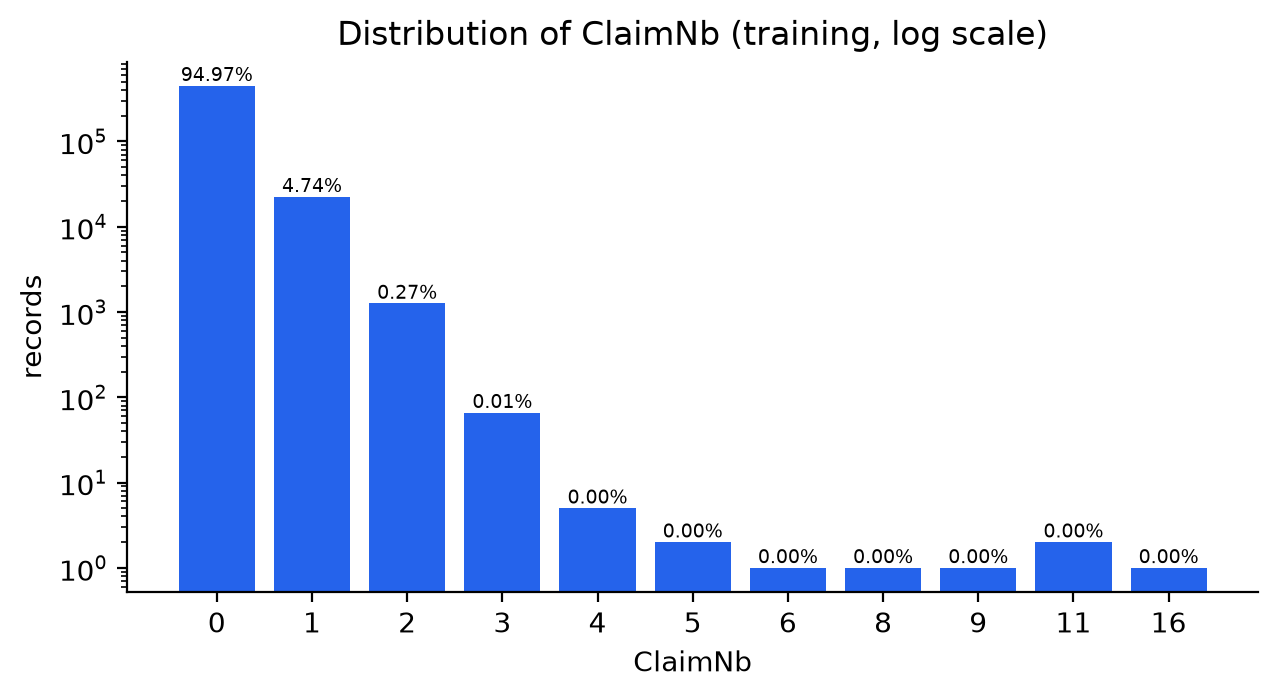

,item,value
0,records with ClaimNb > 4,8.0000
1,claims in those records,71.0000
2,records with Exposure > 1,869.0000
3,records with Exposure ≤ 0.02,"13,465.0000"
4,records with DrivAge = 100,3.0000
5,records with VehAge = 100,11.0000


In [5]:
display(artifacts.localize(tables["eda_claimnb_distribution"], LANG))
plots.show(plots.plot_claimnb(tables["eda_claimnb_distribution"], LANG))
display(artifacts.extremes_table(summary, LANG))

### Insights

Among the training records, 94.97% have `ClaimNb = 0`. The other percentages use a different denominator: of all observed claims, 88.9% are in policies with one claim and 9.9% in policies with two claims.

The tail above four is rare: 8 records add up to 71 claims. These cases are valid and were preserved. Their concentration in a small number of profiles is handled in the profile-based sensitivity of the model comparison.

## 5. Distribution of `Exposure`

**Question.** How is the coverage duration distributed, and how much do very short exposures, exactly one year and more than one year weigh?

,band,records,rows_claim_valid,claims_claim_valid,exposure_valid,rows_rate_subset,exposure_rate_subset,claims_rate_subset,zeros_rate_subset,zero share,rate_per_100_policy_years
0,"(0, 0.02]",13465,13465,376.0000,150.0536,13465,150.0536,376.0000,13106,0.9733,250.5772
1,"(0.02, 0.08]",66879,66879,"1,583.0000","4,269.4100",66879,"4,269.4100","1,583.0000",65388,0.9777,37.0777
2,"(0.08, 0.25]",75529,75529,"3,046.0000","13,042.8100",75529,"13,042.8100","3,046.0000",72655,0.9619,23.3539
3,"(0.25, 0.50]",91750,91750,"4,515.0000","35,885.0100",91750,"35,885.0100","4,515.0000",87534,0.9540,12.5819
4,"(0.50, 0.75]",64735,64735,"4,140.0000","40,998.6700",64735,"40,998.6700","4,140.0000",60842,0.9399,10.0979
5,"(0.75, 1)",43493,43493,"3,294.0000","37,895.4600",43493,"37,895.4600","3,294.0000",40429,0.9296,8.6923
6,= 1,117861,117861,"8,336.0000","117,861.0000",117861,"117,861.0000","8,336.0000",109937,0.9328,7.0727
7,> 1,869,869,29.0000,967.8900,869,967.8900,29.0000,840,0.9666,2.9962
8,exposicao_invalida,0,0,0.0000,0.0000,0,0.0000,0.0000,0,NaN,NaN
9,total,474581,474581,"25,319.0000","251,070.3036",474581,"251,070.3036","25,319.0000",450731,0.9497,10.0844


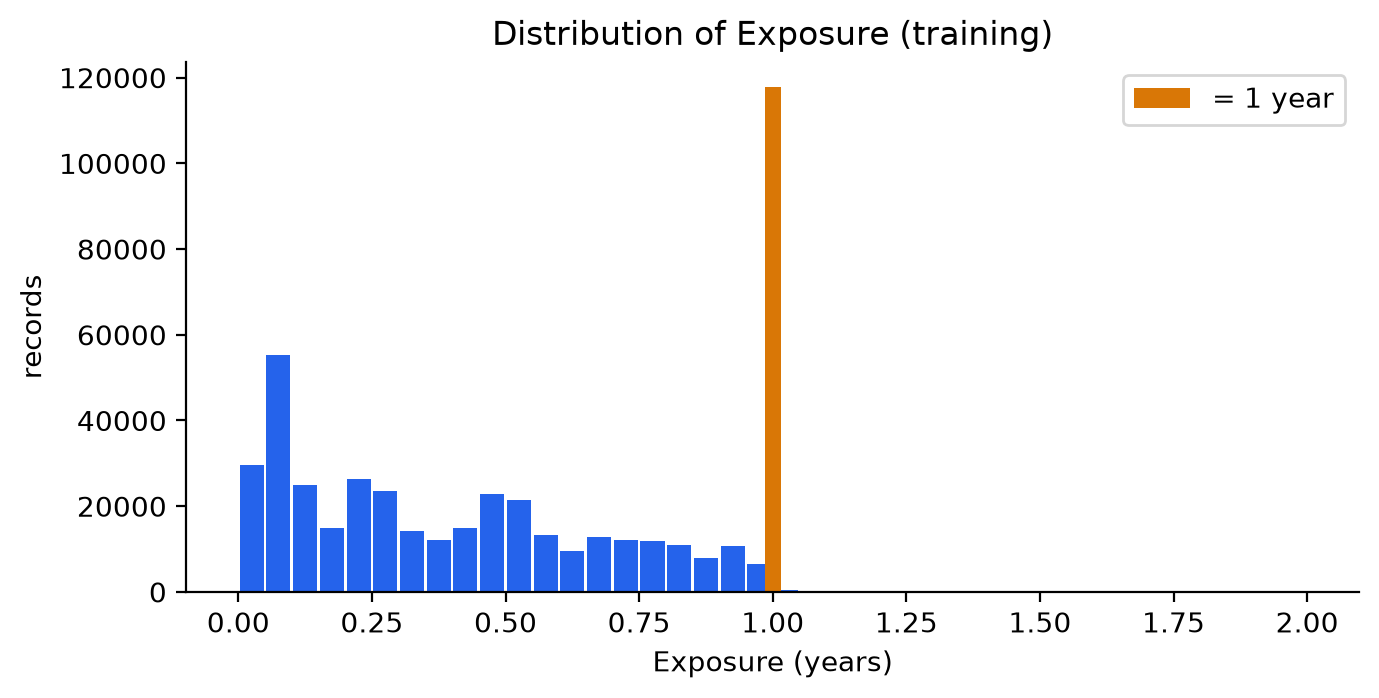

In [6]:
display(artifacts.localize(tables["eda_exposure_bands"], LANG))
plots.show(plots.plot_exposure(tables["eda_exposure_histogram"], LANG))

### Insights

Exposures of exactly one year are 24.8% of the records and 46.9% of total exposure. The `(0; 0.02]` band (about one week) has 13,465 records and the band above one year has 869. The unit is years, according to the dictionary (Dutang & Charpentier, 2018). Exposures above one year are handled as an observed tail, not as errors, because the source describes the policies as observed mostly over one year.

## 6. Frequency by exposure band, age and region

**Question.** How does the rate per 100 policy-years vary by exposure band, vehicle age, driver age and region? Segments with fewer than 500 records or fewer than 25 policy-years are flagged as low support.

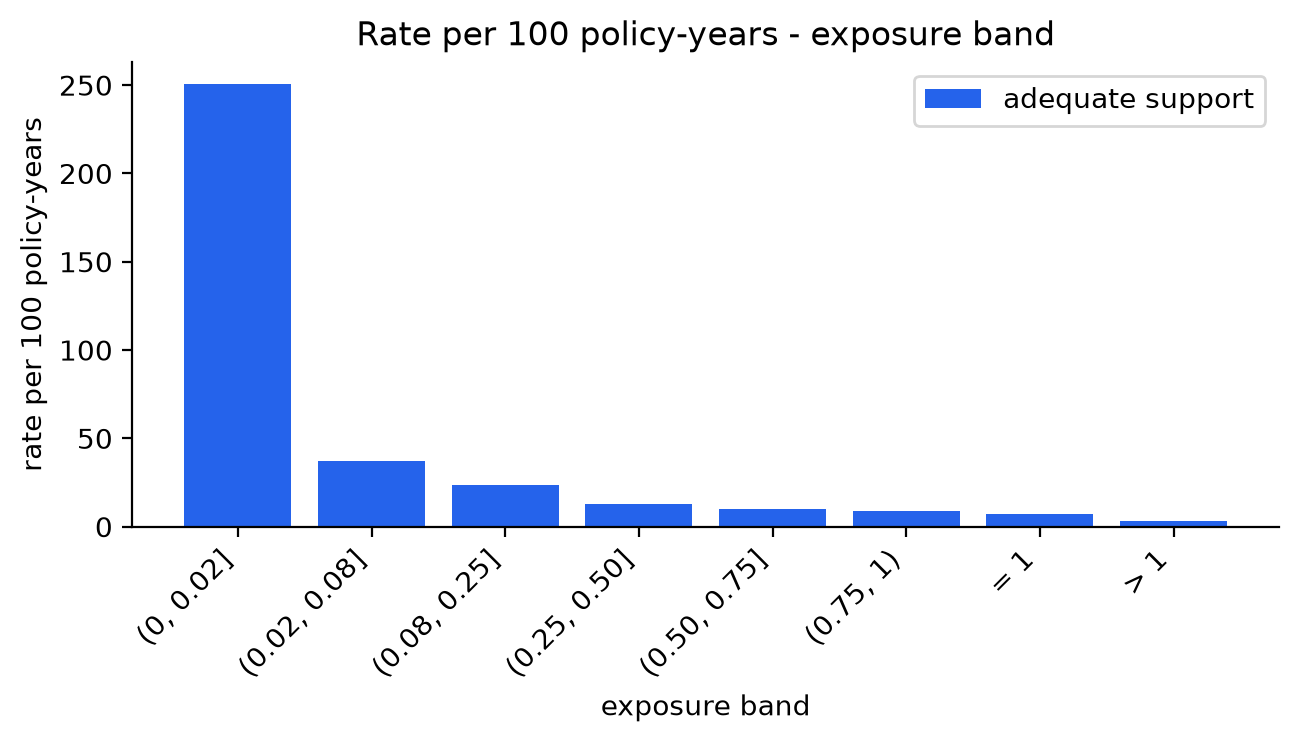

,segment,records,exposure,claims,zeros,zero share,rate per 100 policy-years,low support
0,0-1,90374,"34,638.7546","5,715.0000",84996,0.9405,16.4989,False
1,2-5,134134,"71,307.9284","6,661.0000",127872,0.9533,9.3412,False
2,6-10,120059,"69,272.8475","6,855.0000",113602,0.9462,9.8957,False
3,11-20,124244,"72,285.4168","5,882.0000",118680,0.9552,8.1372,False
4,21+,5770,"3,565.3563",206.0000,5581,0.9672,5.7778,False


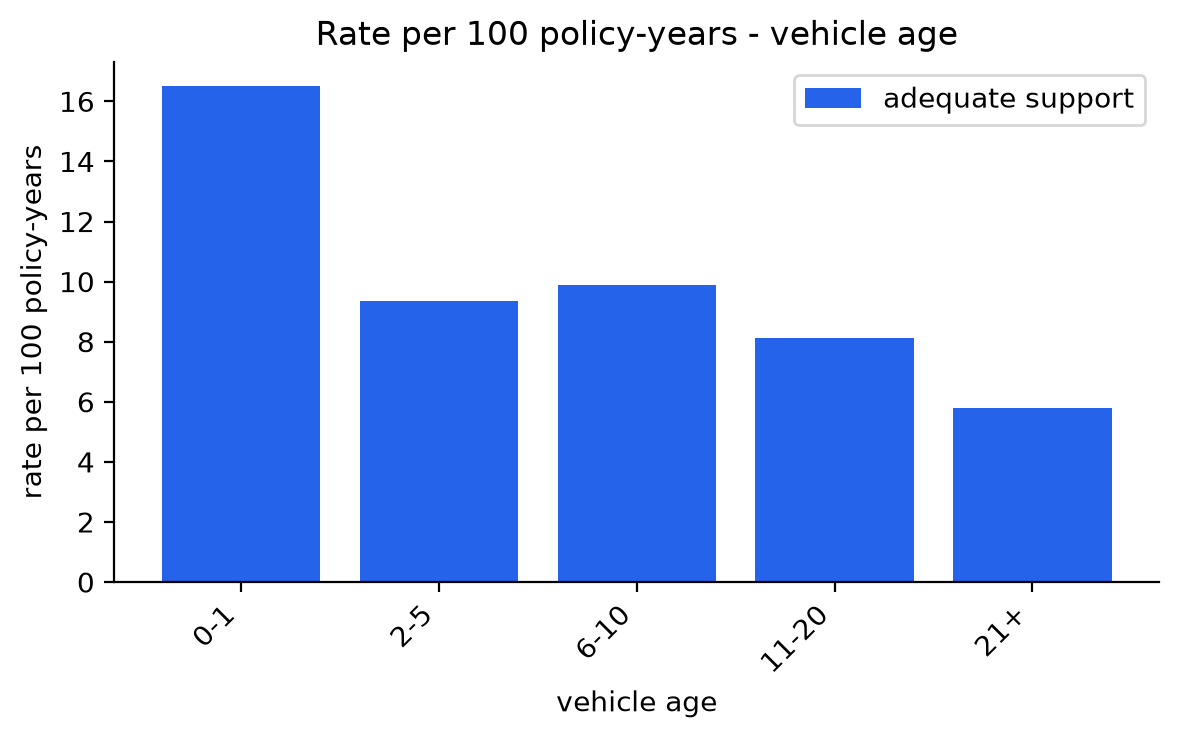

,segment,records,exposure,claims,zeros,zero share,rate per 100 policy-years,low support
0,18-24,21187,"8,824.2567","1,668.0000",19656,0.9277,18.9024,False
1,25-34,98655,"45,279.8467","4,491.0000",94423,0.9571,9.9183,False
2,35-44,119593,"61,141.1634","5,670.0000",114220,0.9551,9.2736,False
3,45-54,114613,"62,874.4777","6,714.0000",108286,0.9448,10.6784,False
4,55-64,69283,"39,302.6415","3,559.0000",65914,0.9514,9.0554,False
5,65-74,35558,"22,524.8696","2,112.0000",33568,0.9440,9.3763,False
6,75+,15692,"11,123.0480","1,105.0000",14664,0.9345,9.9343,False


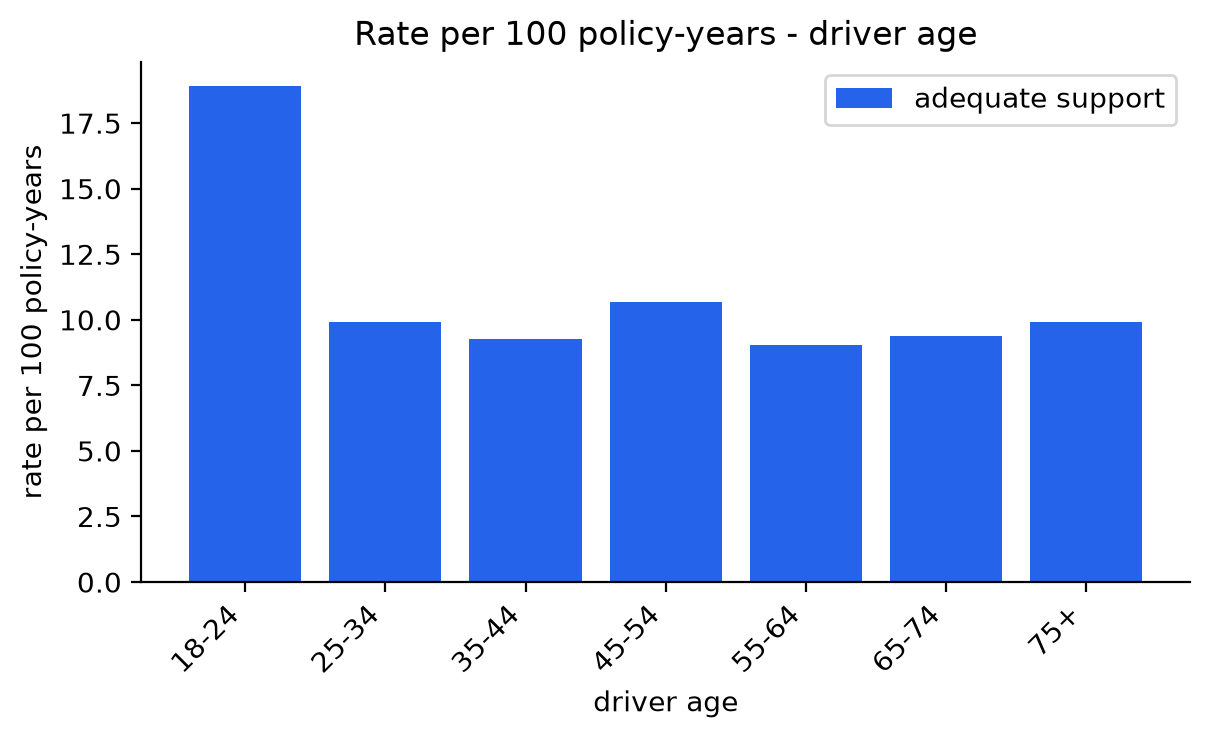

,segment,records,exposure,claims,zeros,zero share,rate per 100 policy-years,low support
0,R11,48970,"21,209.7699","2,784.0000",46384,0.9472,13.1260,False
1,R21,2121,852.0368,120.0000,2010,0.9477,14.0839,False
2,R22,5606,"2,480.5850",297.0000,5320,0.9490,11.9730,False
3,R23,6196,"2,222.4600",212.0000,5999,0.9682,9.5390,False
4,R24,112569,"72,092.1193","6,420.0000",106422,0.9454,8.9053,False
5,R25,7655,"4,707.0442",448.0000,7227,0.9441,9.5177,False
6,R26,7364,"3,525.4488",345.0000,7030,0.9546,9.7860,False
7,R31,19062,"8,023.6161",825.0000,18298,0.9599,10.2821,False
8,R41,9013,"5,625.4010",404.0000,8624,0.9568,7.1817,False
9,R42,1573,866.3412,99.0000,1482,0.9421,11.4274,False


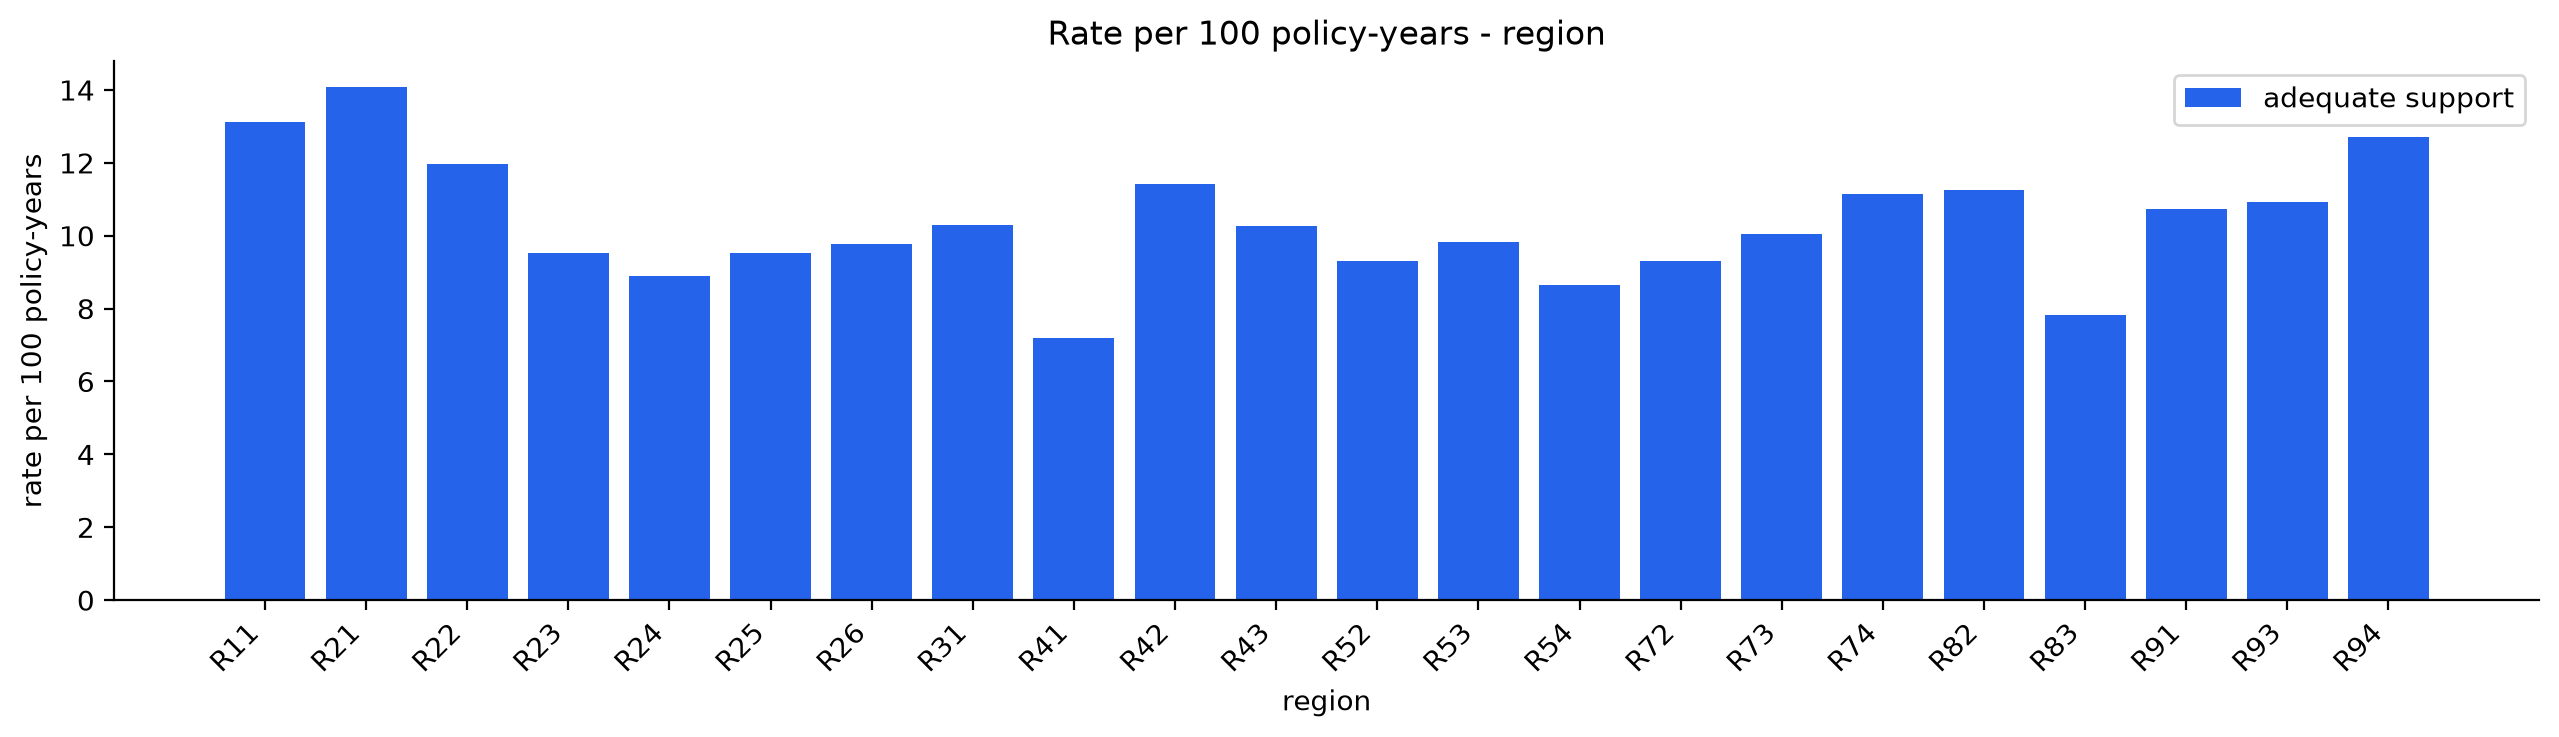

In [7]:
bands = eda.band_rate_table(tables["eda_exposure_bands"])
plots.show(plots.plot_rates(bands, LANG, "band"))
for name, key in (("age_veh", "eda_rate_vehicle_age"),
                  ("age_drv", "eda_rate_driver_age"),
                  ("region", "eda_rate_region")):
    table = tables[key]
    display(artifacts.localize(table, LANG))
    plots.show(plots.plot_rates(table, LANG, name))

### Insights

The rate decreases with coverage duration: 250.6 per 100 policy-years in `(0; 0.02]`, 7.07 at exactly one year and 3.00 above one year. By vehicle age, the rate is 16.5 at 0–1 years and 8.1 at 11–20 years; by driver age, 18.9 at 18–24 and 9.3 at 35–44. Among regions with support, rates range from R41 (7.2) to R21 (14.1). No training segment is low support in the exposure and age bands; low-support regions, when present, appear hatched. All differences are marginal and descriptive.

## 7. Do short exposures persist within profiles?

**Question.** Is the elevated rate of short exposures due to the age composition, or does it persist within strata with support? The reference rate of each stratum (driver age × vehicle age) uses the rows with `Exposure ≥ 0.75`.

,band,records,exposure,observed,expected_ref_rate,ratio_observed_expected,low support
0,"(0, 0.02]",13268,147.4625,371.0000,11.9991,30.9189,False
1,"(0.02, 0.08]",66078,"4,221.5300","1,557.0000",325.1986,4.7878,False
2,"(0.08, 0.25]",74545,"12,881.0000","2,974.0000","1,013.5496",2.9342,False
3,"(0.25, 0.50]",90872,"35,548.5300","4,457.0000","2,776.4421",1.6053,False
4,"(0.50, 0.75]",64104,"40,599.6800","4,088.0000","3,216.9969",1.2708,False
5,"(0.75, 1)",43151,"37,598.1400","3,267.0000","2,934.2332",1.1134,False
6,= 1,117004,"117,004.0000","8,282.0000","8,656.3169",0.9568,False
7,> 1,864,962.6500,29.0000,70.6776,0.4103,False


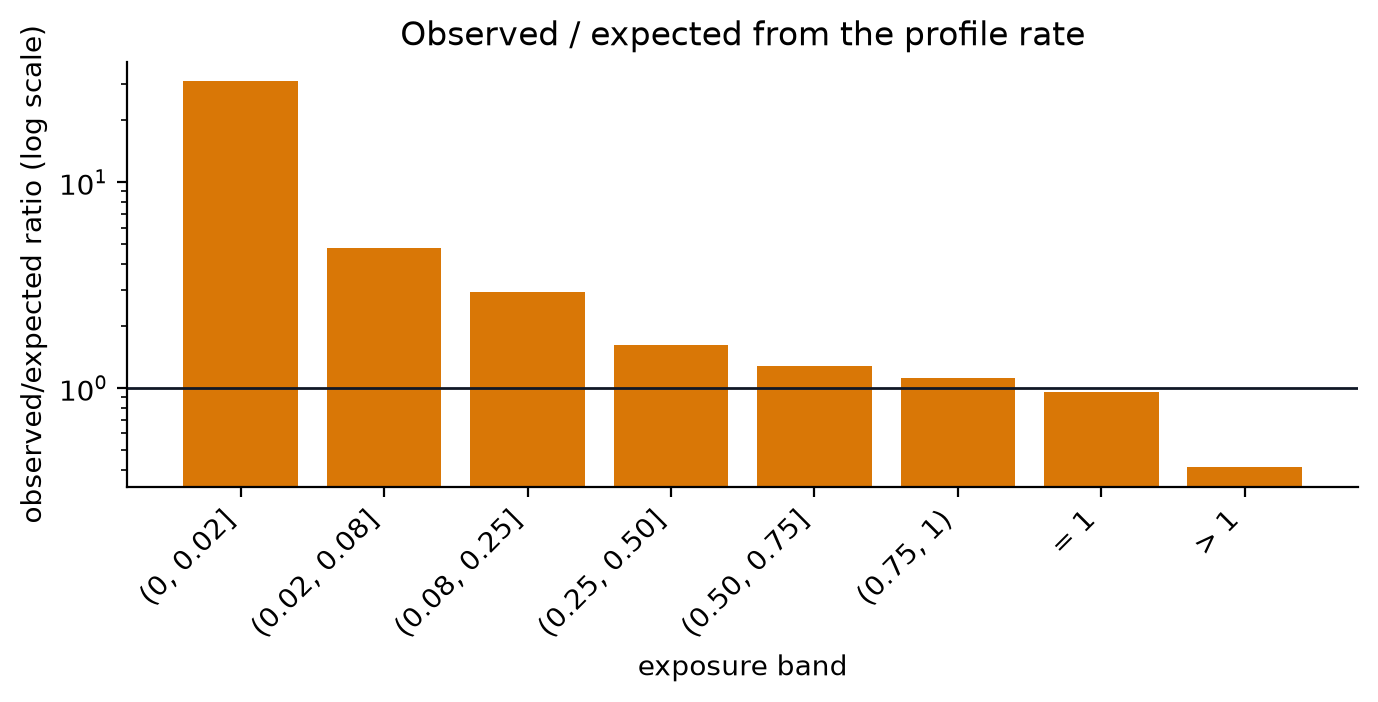

strata_total                           35.0000
strata_with_reference_support          30.0000
short_limit_exposure_le                 0.0800
reference_exposure_ge                   0.7500
strata_supported_in_both               24.0000
strata_short_rate_above_reference      24.0000
median_ratio_short_over_ref             4.1969
min_ratio_short_over_ref                2.7133
pooled_short_ratio_observed_expected    5.7177
dtype: float64

sample_rows                 100000
converged                     True
coefficient_log_exposure    0.3926
naive_se                    0.0164
approx_95_low               0.3605
approx_95_high              0.4247
assumed_by_offset           1.0000
dtype: object

In [8]:
display(artifacts.localize(tables["eda_short_exposure_bands"], LANG))
plots.show(plots.plot_short_check(tables["eda_short_exposure_bands"], LANG))
display(pd.Series(summary["short_exposure_check"]))
display(pd.Series(summary["offset_check"]))

### Insights

In 24 of 24 strata with support in both groups, the rate of rows with `Exposure ≤ 0.08` exceeds the reference rate (median ratio 4.2; minimum 2.7). The observed/expected ratio is 30.9 in `(0; 0.02]`, 4.8 in `(0.02; 0.08]` and 0.96 at exactly one year. The pattern therefore persists within the age strata with support.

This comparison is descriptive. The strata control only driver age and vehicle age, not the other covariates; moreover, the reference (`Exposure ≥ 0.75`) is an analytical choice. The result neither rules out other explanations nor indicates causality.

The `log(Exposure)` offset with coefficient 1 presupposes claims proportional to exposure (Cameron & Trivedi, 2013). As a training diagnostic, the free coefficient of `log(Exposure)` was 0.39 (approximate interval 0.36 to 0.42), far from 1. In validation, the calibration by exposure band of the three candidates will be checked without post hoc recalibration. If the pattern persists, short bands will be underpredicted and long bands overpredicted.

## 8. Category coverage and unknown levels

**Question.** How does the preprocessing handle levels that are rare or absent from the fit? A preprocessor was fitted on a sample of 100,000 training rows and applied to the remaining training rows.

In [9]:
display(artifacts.coverage_table(summary, LANG))
display(pd.Series(summary["unknown_level_check"]["has_other"]))

,covariate,rows mapped to OTHER or reference,levels pooled in the fit
0,Area,0,-
1,VehPower,4700,"13, 14, 15"
2,VehBrand,0,-
3,VehGas,0,-
4,Region,3618,"R21, R42, R43"


Area        False
VehPower     True
VehBrand    False
VehGas      False
Region       True
dtype: bool

### Insights

Levels with fewer than 500 fit rows are pooled into `OTHER`. Among the 374,581 training rows outside the sample, 3,618 (`Region`) and 4,700 (`VehPower`) were mapped to `OTHER`, and the design matrix remained finite. This verifies the handling of unknown levels with training data; the rule is applied to validation and test without refitting.

## 9. Limits of the evidence

**Question.** What does this EDA not allow concluding?

In [10]:
pd.Series({"partition": "train", "rows": len(train),
           "has_dates": False, "has_higher_unit_id": False})

partition              train
rows                  474581
has_dates              False
has_higher_unit_id     False
dtype: object

### Insights

The schema has neither dates nor a higher-level unit identifier; covariate availability at the estimation date is a hypothesis, and `BonusMalus`, whose measurement time is unknown, is left out of the main specification (Dutang & Charpentier, 2018). Segment rates are marginal and do not control for the other covariates. The evidence holds within the benchmark and is descriptive. The same data set has been studied in other work (Noll et al., 2020); the present analysis does not reproduce it. The modeling sequence follows the count-model literature (Fávero & Belfiore, 2017).

## References

- Cameron, A. C., & Trivedi, P. K. (2013). *Regression Analysis of Count Data* (2nd ed.). Cambridge University Press. https://doi.org/10.1017/CBO9781139013567
- Dutang, C., & Charpentier, A. (2018). *CASdatasets: Insurance datasets* (freMTPL2freq). https://dutangc.github.io/CASdatasets/reference/freMTPL.html
- Dwork, C., Feldman, V., Hardt, M., Pitassi, T., Reingold, O., & Roth, A. (2015). [Generalization in adaptive data analysis and holdout reuse](https://proceedings.neurips.cc/paper_files/paper/2015/hash/bad5f33780c42f2588878a9d07405083-Abstract.html). *Advances in Neural Information Processing Systems, 28*.
- Fávero, L. P., & Belfiore, P. (2017). *Manual de Análise de Dados: Estatística e Modelagem Multivariada com Excel, SPSS e Stata*. Rio de Janeiro: GEN LTC. ISBN 978-85-352-7087-7.
- Noll, A., Salzmann, R., & Wüthrich, M. V. (2020). Case study: French motor third-party liability claims (revised version; first posted in 2018). *SSRN*. https://doi.org/10.2139/ssrn.3164764
- Wickham, H., & Grolemund, G. (2017). [*R for Data Science*](https://r4ds.had.co.nz/model-intro.html) (1st ed., ch. 22). O’Reilly Media.